# 10 In-Class Assignment: Eigenproblems

<img src="https://campusinvolvement.umich.edu/files/campusinvolvement/field/image/helmets.jpg" alt="Image of two football helmets hitting each other. One is MSU and one is UofM which matches an example we will do in class" width="50%">

Image from: [https://campusinvolvement.umich.edu/](https://campusinvolvement.umich.edu/) 

# Siddak Marwaha


---
<a name=Pre-Class-Review></a>
## 1. Pre Class Review

**Definition.** Let $A$ be an $n\times n$ matrix.  A non-zero vector $x$ in $\mathbb{R}^n$ is called an **eigenvector** of $A$ such that:

$$Ax=\lambda x$$

for some scalar $\lambda$, which will be called **eigenvalue** corresponding to $x$.

The above can be rewritten as the following homogeneous equation:

$$
(A-\lambda I_n)x = 0
$$
The trivial solution is $x=0$. To find the eigenvalues, you need the determinant of $A - \lambda I_n $ to be zero, i.e.
$$|A-\lambda I_n| = 0$$ 
Once you know the eigenvalues $\lambda$, you use $(A-\lambda I_n)x = 0$ to find the corresponding eigenvectors.


&#9989;**<font color=red>QUESTION:</font>** Find the eigenvalues of $$A=\begin{bmatrix}
2 & 3  \\ 
3 & -6    
\end{bmatrix}$$ and the corresponding eigenvectors.

**-7,3**



---
<a name=Introduction-to-Markov-Models></a>
## 2.  Markov Models


>In probability theory, a Markov model is a stochastic model used to model randomly changing systems. 
It is assumed that future states depend only on the current state, not on the events that occurred before it.
>
> <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/2/2b/Markovkate_01.svg/1126px-Markovkate_01.svg.png" width=25%>
> A diagram representing a two-state Markov process, with the states labelled E and A. 
Each number represents the probability of the Markov process changing from one state to another state, with the direction indicated by the arrow. 
For example, if the Markov process is in state A, then the probability it changes to state E is 0.4, while the probability it remains in state A is 0.6.

From: [Wikipedia](https://en.wikipedia.org/wiki/Markov_model)

The above state model can be represented by a transition matrix. 

$$\begin{array}{cc}
& \text{Current State}  \\
P =  &
\begin{bmatrix}
    p_{A\rightarrow A} & p_{E\rightarrow A}  \\
    p_{A\rightarrow E} & p_{E\rightarrow E} 
\end{bmatrix}
\end{array}
\text{Next state}$$

In other words we can write the above as follows:

In [1]:
%matplotlib inline
import matplotlib.pylab as plt
import numpy as np
import sympy as sym
sym.init_printing(use_unicode=True)

In [2]:
A = np.matrix([[0.6, 0.7],[0.4, 0.3]])
sym.Matrix(A)

⎡0.6  0.7⎤
⎢        ⎥
⎣0.4  0.3⎦

Notice how the columns in the matrix all add to one. This is because all of the transition probabilities out of a matrix must add to 100 percent. 

A Markov matrix $P$ always has an eigenvalue of $1$. All other eigenvalues are in absolute value smaller or equal to $1$.

Now, consider the following house map with cats in each room...

At each time step, there is an equal probability of a cat staying in their current room or moving to a new room. 
If a cat chooses to leave a room, then there is an equal chance of that cat picking any of the doors in the room to leave. 

<img src="https://lh4.googleusercontent.com/CGFHfJgtrPu-2bZPhPul1ll8B3tqC1Vs8jRwnZ13v8MqRAagWhrSmJ0cznYIP3ePg5co5AVI8g=w712" alt="Top down diagram of a house with three rooms (see text for more description" width="50%">

&#9989;**<font color=red>DO THIS :</font>** Try to draw a Markov chain (Markov matrix) for the above system of equations. Be prepared to share your diagram with the class. 

A Markov chain can be represented as a Markov transition model of the form $Ax=b$. 
Where $A$ is your probability tranisition matrix (often represented as a $P$ instead of an $A$). 
$x$ is the state before the transition and $b$ is the state after the transition.

&#9989;**<font color=red>QUESTION:</font>** Generate a Markov transition model represented as a matrix $P$ of the form:
$$
\begin{array}{ccc}
& \text{Current Room}  \\
P =  &
\begin{bmatrix}
    p_{11} & p_{12} & p_{13} \\
    p_{21} & p_{22} & p_{23} \\
    p_{31} & p_{32} & p_{33} 
\end{bmatrix}
\end{array}
\text{Next Room}
$$

Where $p_{ij}$ are probability transitions of the cat moving between rooms (from room $j$ to room $i$):

In [12]:
##put your answer here
P = np.matrix([[0.5,2/6,1/4],[2/6,0.5,1/4],[1/6,1/6,0.5]])


In [13]:
from answercheck import checkanswer

checkanswer.matrix(P,'1001a6fa07727caf8ce05226b765542c');

Testing [[0.5     0.33333 0.25   ]
 [0.33333 0.5     0.25   ]
 [0.16667 0.16667 0.5    ]]
Answer seems to be correct



&#9989;**<font color=red>QUESTION:</font>**  Let's assume that the system starts with; 6 cats in room 1, 15 cats in room 2, and 3 cats in room 3. On average, how many cats will be in each room after one time step (Store the values in a vector called ```current_state```)?

In [14]:
#Put your answer to the above question here.
room1 = 6*0.5+15*1/3+3*1/4
room2 = 0.5*15+1/3*6+1/4*3
room3 = 0.5*3 + 1/6*6+1/6*15
current_state = [room1,room2,room3]

In [15]:
from answercheck import checkanswer

checkanswer.vector(current_state,'98d5519be82a0585654de5eda3a7f397');


    Trying to convert to a array matrix using ```A = np.matrix(A)```.

Testing [[ 8.75 10.25  5.  ]]
Answer seems to be correct



&#9989;**<font color=red>QUESTION:</font>** The following code will plot the expected number of cats as a function of time ($t$).  When this system converges, what is the steady state?

[[9.00002533]
 [9.00002548]
 [5.99994919]]


~/opt/anaconda3/lib/python3.9/site-packages/numpy/core/shape_base.py:65: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = asanyarray(ary)


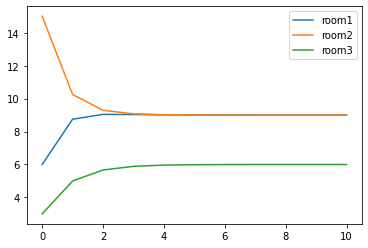

In [16]:
#Define Start State
room1 = [6]
room2 = [15]
room3 = [3]

current_state = np.matrix([room1, room2, room3])

for i in range(10):
    #update Current State
    current_state = P*current_state
    
    #Store history for each room
    room1.append(current_state[0])
    room2.append(current_state[1])
    room3.append(current_state[2])
    
plt.plot(room1, label="room1");
plt.plot(room2, label="room2");
plt.plot(room3, label="room3");
plt.legend();
print(current_state)

In [17]:
qaz = np.matrix([1,2,3])
print(qaz)

[[1 2 3]]


In the steady state, there's 9 cats in room 1 and 2, and 6 in room 3.

Inspect the generated graph and put your answer to the above question here

&#9989;**<font color=red>QUESTION:</font>**  Calculate the eigenvalues and eigenvectors of your $P$ transition matrix.  

In [47]:
##put your answer here
np.linalg.eig(P)

(array([1.        , 0.16666667, 0.33333333]),
 matrix([[-6.39602149e-01, -7.07106781e-01, -4.08248290e-01],
         [-6.39602149e-01,  7.07106781e-01, -4.08248290e-01],
         [-4.26401433e-01, -4.12648555e-16,  8.16496581e-01]]))

The eigenvector associated with the eigenvalue of 1 represents the steady state probability for our original transition matrix $P$.  

&#9989;**<font color=red>DO THIS:</font>** make a new vector called ```steadystate``` from the eigenvector of your $P$ matrix with a eigenvalue of 1.

In [48]:
## Put your answer here
steadystate = np.matrix([3/2,3/2,1])

Since the ```steadystate``` vectors represent long term probabilities, they should sum to one (1).  However, many programming libraries (including numpy) return "normalized" eigenvectors to length of 1 (i.e. norm(e)==1). 

&#9989;**<font color=red>DO THIS:</font>**  Correct for the normalization by multiplying the ```steadystate``` eigenvector by a constant such that the sum of the vector elements add to 1. 

In [52]:
#Put your answer here
steadystate = (steadystate)/4

&#9989;**<font color=red>DO THIS:</font>**  The steady state represents the proportion of cats that will be in each room, but since we know the initial number of cats, we can find how these cats arrange themselves in the steady state by multiplying `steadystate` by the total number of cats.  The resulting vector should be identical to the steady state in the above chart.

In [54]:
steadystate*24

matrix([[9., 9., 6.]])

&#9989;**<font color=red>QUESTION:</font>** Why does the sum of the numbers at every stage remain the same? 


The sum of the numbers remains the same since the total number of cats does not change in the system




---
<a name=Another-Markov-Model-Example></a>
## 3. Another Markov Model Example



> A sports broadcaster wishes to predict how many Michigan residents prefer University of Michigan teams and how many prefer Michigan State teams. 
She noticed that, year after year, most people stick with their preferred team; however, about 5% of Michigan fans switch to Michigan State, and about 3% of Michigan State fans switch to Michigan each year. 
However, there is no noticeable difference in the state's population of 10 million's preference at large; in other words, it seems Michigan sports fans have reached a stationary distribution. What might that be?
 <p style="text-align: right;">  This problem is from https://brilliant.org/wiki/stationary-distributions/ </p>

&#9989;**<font color=red>DO THIS:</font>** Try to draw a Markov chain for the above system of equations. Discuss your diagram with your classmate.

&#9989; **<font color=red>QUESTION:</font>**  Write a system of linear equations that represents how the populations change each year. Check your equations by writing the matrix ```P``` for the probability transitions matrix in your equations. Make sure your first row/column represents MSU and the second row/column represents UofM. 

- umich = 0.95mich +0.03ms
- michstate = 0.97ms + 0.05mich

In [118]:
P = np.matrix([[0.97, 0.05],
              [0.03, 0.95]])


In [119]:
from answercheck import checkanswer

checkanswer.vector(P,'1d3f7cbebef4b610f3b0a2d97609c81f');


    Trying to convert to a column vector using ```A = A.T```.

Testing [[0.97 0.03]
 [0.05 0.95]]
Answer seems to be correct



&#9989; **<font color=red>QUESTION:</font>**   Use Numpy to calculate the eigenvalues and eigenvectors of your $P$ transition matrix.  

In [131]:
#Put the answer to the above quesiton here.
np.linalg.eig(P)

(array([1.  , 0.92]),
 matrix([[ 0.85749293, -0.70710678],
         [ 0.51449576,  0.70710678]]))

&#9989; **<font color=red>QUESTION:</font>**   Assuming both teams start with 500,000 fans each (so 1,000,000 fans total), what is the steady state of this model? (I.e. in the long term how many Spartan and Wolverine fans will there be?).

In [139]:
#Put your answer here
steadystate = np.matrix([5/3,1])
steadystate = (steadystate)*3/8
steadystate = steadystate * 1000000

In [148]:
steadystate
spartans = steadystate[0,0]
wolverines = steadystate[0,1]

In [149]:
from answercheck import checkanswer

checkanswer.float(spartans,'06d263de629f4dbe51eafd524b69ddd9');


    Trying to convert to a float using ```A = float(A)```.

Testing 625000.0
Answer seems to be correct



In [150]:
from answercheck import checkanswer

checkanswer.float(wolverines,'62d63699c8f7b886ec9b3cb651bba753');


    Trying to convert to a float using ```A = float(A)```.

Testing 375000.0
Answer seems to be correct



---
<a name="Page-Rank"></a>
## 4. Page Rank

Google's famous "Page Rank" algorithm is just a calculation of the likelyhood that a person will reach a particulare web page.  

> To explain the algorithm, we model the web as an oriented graph. The vertices are the pages, and the oriented edges are the links between pages. As we just explained, each page corresponds to a different url. Hence, a website may contain many pages. The model makes no difference between the individual pages of a website and its front page. But, most likely, the algorithm will rank better the front page of an important website.

From: http://blog.kleinproject.org/?p=280

Using the vocabulary from this course, a simplified version of Google's Page Rank is the steady state probabilities of the Markov State Model where each node in the network is a page and each transition probability is calculated as an equal probablility from the current page to its linked pages.  

For this problem, consider the following Markov model of a generic webpage. 

<img src="https://lh4.googleusercontent.com/LFe_yWxZA_F_Ze3PSMqwQds9zUOgjnzGP6pxPZJYAGjRTj_BKNqvcDxGHhbZg1Y3iSVOFPb9MW_a8JvwrdhfU3Av7zC13JO_faPs0WC7AziKWMwrwKkqdl6RJmxq=w477"></a>

&#9989; <font color=red>**QUESTION:**</font> Find the state transition matrix for the above system. Let's consider Home = state 1, About = state 2, Resume = state 3, Blog = state 4 and let $p_{ij}$ be the probability transition from state $j$ to state $i$. 

In [152]:
# Define the matrix here
P = np.matrix([[0.25, 0.5, 0.2, 0.1],
             [0.2, 0.5, 0, 0],
             [0.25, 0, 0.8, 0],
             [0.3, 0, 0, 0.9]])

&#9989; <font color=red>**QUESTION:**</font> Using ```numpy``` calculate the eigenvalues and eigenvectors of the model.

In [153]:
# Calculate the eigenvalues and eigenvectors here
np.linalg.eig(P)

(array([-0.03080559,  0.62824572,  1.        ,  0.85255987]),
 matrix([[ 0.86503305, -0.38434776,  0.29207197, -0.12506269],
         [-0.32593216, -0.59939273,  0.11682879, -0.0709455 ],
         [-0.26029948,  0.55944422,  0.36508996, -0.59485825],
         [-0.27880142,  0.42429627,  0.87621591,  0.79086644]]))

&#9989; <font color=red>**QUESTION:**</font> Again, calculate the steady state of this model. Remember that the steady state vector is an eigenvector corresponding to the eigenvalue $1$ which is scaled so that the sum of its entries is $1$. 

In [169]:
# Put your code here
steadystate = np.matrix([1/3,2/15,5/12,1])
steadystate = steadystate*3/5.65
steadystate*10000

matrix([[1769.91150442,  707.96460177, 2212.38938053, 5309.73451327]])

&#9989; <font color=red>**QUESTION:**</font> Based on the long term steady state vector that you calculated, which page are people likely to spend the most time? Explain how you came up with the answer.

**Blog.**

&#9989; <font color=red>**QUESTION:**</font> If exactly 10,000 people are on the website at a time (assume this is constant), estimate how many people will be on the About page over the long term?  Explain how you came up with your answer.

**around 708. Multiplied steadystate by 10000 to get this answer.**

----

Written by Dr. Dirk Colbry, Michigan State University
<a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by-nc/4.0/88x31.png" /></a><br />This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/">Creative Commons Attribution-NonCommercial 4.0 International License</a>.

----